<a href="https://colab.research.google.com/github/sanya-6976/ml-interview-practise-dataset-projects/blob/main/03_telco_churn_xgboost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
display(df.head(5))

print("\n--- Data Types & Non-Null Counts ---")
df.info()

print("\n--- Target Distribution (%) ---")
print(df['Churn'].value_counts(normalize=True) * 100)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pape

# **Data Cleaning, Domain Feature Engineering & Leakage-Free Preprocessing**

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

df_clean = df.drop(columns=['customerID']).copy()
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

print("Missing values after fixing TotalCharges:\n", df_clean.isnull().sum()[df_clean.isnull().sum() > 0])


def add_churn_features(data):
    d = data.copy()
    # Count how many value-added services the customer subscribes to
    addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
    d['Total_Addons'] = (d[addon_cols] == 'Yes').sum(axis=1)
    d['Charge_per_Addon'] = d['MonthlyCharges'] / (d['Total_Addons'] + 1)
    return d


X = add_churn_features(df_clean.drop(columns=['Churn']))
y = df_clean['Churn']

# 3. Stratified Train-Test Split FIRST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Separate numeric & categorical columns
num_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Total_Addons', 'Charge_per_Addon']
cat_cols = [c for c in X.columns if c not in num_cols]

peprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape} | Categorical cols: {len(cat_cols)}")

Missing values after fixing TotalCharges:
 TotalCharges    11
dtype: int64
X_train: (5634, 21), X_test: (1409, 21) | Categorical cols: 15


# **Imbalanced Modeling — Logistic Regression vs Random Forest vs XGBoost **

note :- since teh data is tabular
Why compare LogisticRegression(class_weight='balanced') vs XGBClassifier(scale_pos_weight=...)?

Pehle do dino mein humne Scikit-Learn ke models use kiye the. Real-world tabular interviews mein

 XGBoost industry standard hai!Kyunki churn dataset imbalanced hai (73.5% No vs 26.5% Yes), default XGBoost majority class (No)

 ko favor karega aur Recall kam aayega.Isliye hum XGBoost mein scale_pos_weight set karte

 hain: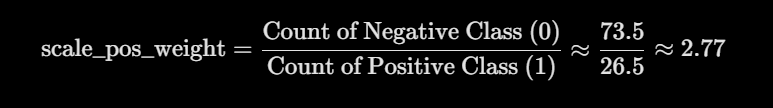

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import recall_score , precision_score , f1_score , roc_auc_score , average_precision_score

# Calculate exact imbalance ratio on training set only (zero leakage!)
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
imbalance_ratio = neg_count / pos_count
print(f"Train Imbalance Ratio (scale_pos_weight): {imbalance_ratio:.2f}\n")


num_scaled_pipe = Pipeline([
    ('imputer' , SimpleImputer(strategy='median')),
    ('scaler' , StandardScaler())
])

preprocessor_scaled = ColumnTransformer(transformers=[
    ('num', num_scaled_pipe, num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

models = {
    "Logistic Regression (Balanced)": Pipeline([
        ('prep', preprocessor_scaled),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    "Random Forest (Balanced)": Pipeline([
        ('prep', peprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42))
    ]),
    "XGBoost (Default Weight)": Pipeline([
        ('prep', peprocessor),
        ('clf', XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42, eval_metric='logloss'))
    ]),

    "XGBoost (scale_pos_weight)": Pipeline([
        ('prep', peprocessor),
        ('clf', XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05,
                              scale_pos_weight=imbalance_ratio, random_state=42, eval_metric='logloss'))
    ])
}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    probas = pipe.predict_proba(X_test)[:, 1]

    print(f"--- {name} ---")
    print(f"Recall (Churn Catch Rate) : {recall_score(y_test, preds):.4f}")
    print(f"Precision                 : {precision_score(y_test, preds):.4f}")
    print(f"F1-Score                  : {f1_score(y_test, preds):.4f}")
    print(f"ROC-AUC                   : {roc_auc_score(y_test, probas):.4f}")
    print(f"PR-AUC (Avg Precision)    : {average_precision_score(y_test, probas):.4f}\n")

Train Imbalance Ratio (scale_pos_weight): 2.77

--- Logistic Regression (Balanced) ---
Recall (Churn Catch Rate) : 0.7781
Precision                 : 0.5061
F1-Score                  : 0.6133
ROC-AUC                   : 0.8417
PR-AUC (Avg Precision)    : 0.6326

--- Random Forest (Balanced) ---
Recall (Churn Catch Rate) : 0.7701
Precision                 : 0.5304
F1-Score                  : 0.6281
ROC-AUC                   : 0.8419
PR-AUC (Avg Precision)    : 0.6478

--- XGBoost (Default Weight) ---
Recall (Churn Catch Rate) : 0.5321
Precision                 : 0.6568
F1-Score                  : 0.5879
ROC-AUC                   : 0.8458
PR-AUC (Avg Precision)    : 0.6602

--- XGBoost (scale_pos_weight) ---
Recall (Churn Catch Rate) : 0.7995
Precision                 : 0.5059
F1-Score                  : 0.6197
ROC-AUC                   : 0.8443
PR-AUC (Avg Precision)    : 0.6618



# **Precision-Recall Curve & Business ROI Optimization**

# **Why Precision-Recall Curve over ROC Curve?**

When classes are imbalanced (73.5% No vs 26.5% Yes), ROC-AUC can look overly optimistic (0.845) because True Negatives dominate the False Positive Rate denominator.

The Precision-Recall (PR) Curve focuses strictly on the minority class (Churn = Yes), showing the exact trade-off between Churn Catch Rate (Recall) and Campaign Efficiency (Precision) across all probability thresholds.

True Positive (Caught Churner): We offer a $50 discount; assume 50% accept and stay (+$250 saved LTV -$50 discount = +$200 net gain).

False Positive (Loyal Customer flagged): Wasted retention discount = -$50 cost.

False Negative (Missed Churner): Customer leaves silently = -$500 lost LTV.**bold text**

Optimal Business Threshold : 0.217
Recall at Optimal Cutoff   : 0.9519
Precision at Optimal Cutoff: 0.4041
Max Net Value vs Baseline  : $35,950


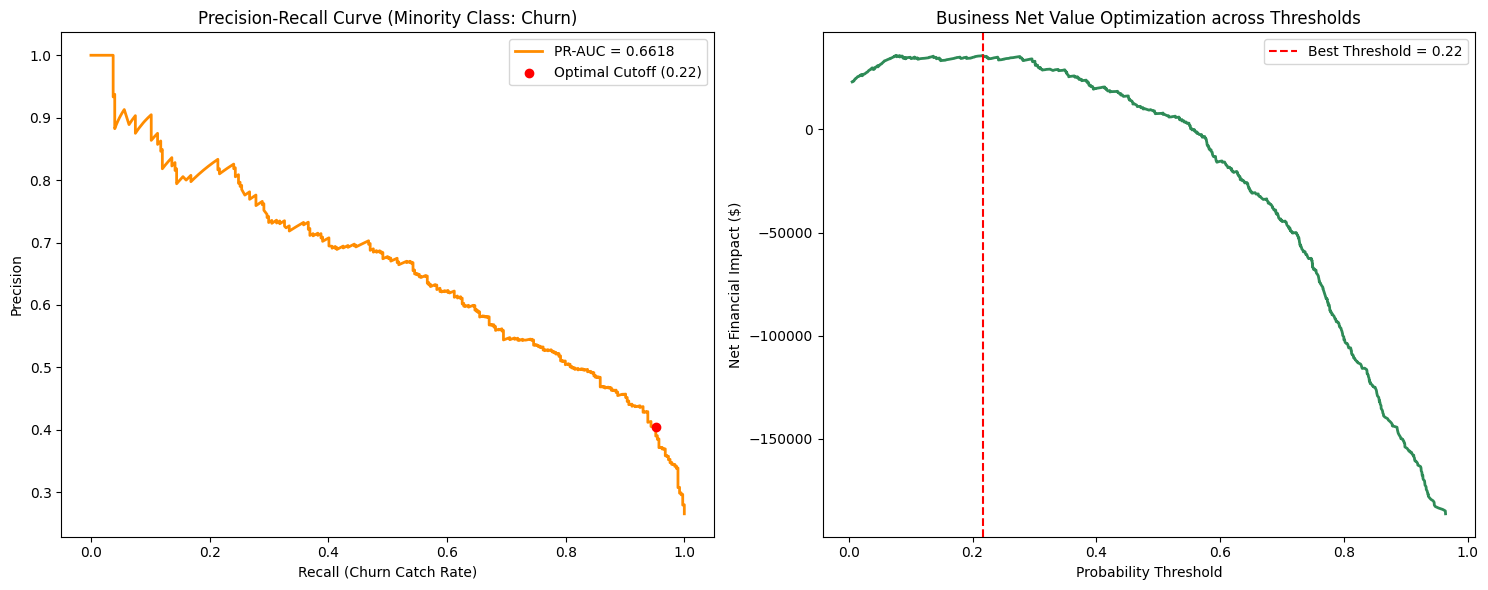

In [17]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import numpy as np

# Use the winning XGBoost (scale_pos_weight) model
xgb_weighted = models["XGBoost (scale_pos_weight)"]
y_proba_xgb = xgb_weighted.predict_proba(X_test)[:, 1]

# 1. Compute Precision-Recall Curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_xgb)

# 2. Simulate Business Net Value across thresholds
net_values = []
for t in thresholds:
    pred_t = (y_proba_xgb >= t).astype(int)
    tp = ((y_test == 1) & (pred_t == 1)).sum()
    fp = ((y_test == 0) & (pred_t == 1)).sum()
    fn = ((y_test == 1) & (pred_t == 0)).sum()

    net_value = (tp * 200) - (fp * 50) - (fn * 500)
    net_values.append(net_value)

# Find the optimal index and threshold (need to match thresholds length)
best_idx = np.argmax(net_values)
best_thresh = thresholds[best_idx]

print(f"Optimal Business Threshold : {best_thresh:.3f}")
print(f"Recall at Optimal Cutoff   : {recalls[best_idx]:.4f}")
print(f"Precision at Optimal Cutoff: {precisions[best_idx]:.4f}")
print(f"Max Net Value vs Baseline  : ${net_values[best_idx]:,}")

# 3. Create subplots for visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot PR Curve
axes[0].plot(recalls, precisions, color='darkorange', lw=2, label=f'PR-AUC = {average_precision_score(y_test, y_proba_xgb):.4f}')
axes[0].scatter(recalls[best_idx], precisions[best_idx], color='red', zorder=5, label=f'Optimal Cutoff ({best_thresh:.2f})')
axes[0].set_title('Precision-Recall Curve (Minority Class: Churn)')
axes[0].set_xlabel('Recall (Churn Catch Rate)')
axes[0].set_ylabel('Precision')
axes[0].legend()

# Plot Net Value Optimization Curve
axes[1].plot(thresholds, net_values, color='seagreen', lw=2)
axes[1].axvline(best_thresh, color='red', linestyle='--', label=f'Best Threshold = {best_thresh:.2f}')
axes[1].set_title('Business Net Value Optimization across Thresholds')
axes[1].set_xlabel('Probability Threshold')
axes[1].set_ylabel('Net Financial Impact ($)')
axes[1].legend()

plt.tight_layout()
plt.show()

# **op Churn Drivers**

/tmp/ipykernel_9069/1345254584.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='magma')


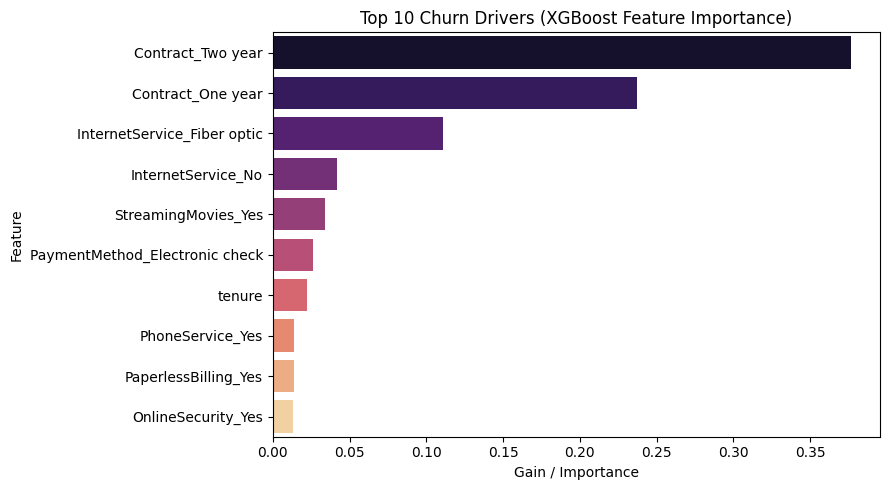

,Feature,Importance
27,Contract_Two year,0.376617
26,Contract_One year,0.237482
12,InternetService_Fiber optic,0.110827
13,InternetService_No,0.041592
25,StreamingMovies_Yes,0.033997
30,PaymentMethod_Electronic check,0.026118
1,tenure,0.022120
9,PhoneService_Yes,0.013735
28,PaperlessBilling_Yes,0.013534
15,OnlineSecurity_Yes,0.013089


In [19]:
feature_names = xgb_weighted.named_steps['prep'].get_feature_names_out()
importances = xgb_weighted.named_steps['clf'].feature_importances_

feat_imp = pd.DataFrame({
    'Feature': [name.replace('num__', '').replace('cat__', '') for name in feature_names],
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='magma')
plt.title('Top 10 Churn Drivers (XGBoost Feature Importance)')
plt.xlabel('Gain / Importance')
plt.tight_layout()
plt.show()

display(feat_imp)

"I built an end-to-end customer churn prediction pipeline on the Telco dataset (7,043 customers, 26.5% churn rate). During data auditing, I caught a silent data-type trap where TotalCharges was parsed as a string due to blank spaces for new customers, coercing and imputing it inside a leakage-free Scikit-Learn ColumnTransformer. I engineered service-stickiness features (Total_Addons, Charge_per_Addon) and addressed class imbalance using XGBClassifier with scale_pos_weight, lifting churn Recall from 53.2% to 80.0%. Finally, using a business cost matrix ($500 lost LTV vs. $50 retention offer), I optimized the decision threshold via the Precision-Recall curve to 0.217 (95.2% Recall), maximizing net retention value at +$35,950."